In [112]:
!pip install uncertainties

In [113]:
import pandas as pd
import numpy as np
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt
from uncertainties import ufloat
import uncertainties.unumpy as unp

plt.rcParams.update({"font.family": "Times New Roman", "mathtext.fontset": "cm"})

In [114]:
colors1 = ["#9e9ac8", "#756bb1", "#54278f"]

In [115]:
workbook = pd.read_excel("2026-10-09_HallEffect.xlsx", sheet_name=["VvsB1", "VvsB2", "VvsB3", "VvsIp", "VvsTheta", "BvsI"])
workbook["VvsB3"].head(3)

,I_P[mA],I_B[A],V_H[mV]
0,9.87,0.051,1.4
1,9.41,0.092,2.1
2,9.71,0.150,3.2


In [116]:
workbook["BvsI"].head(3)

,I_B[mA],B[mT]
0,100,11.4
1,205,21.7
2,302,30.9


In [117]:
voltage_stdv = 1 / 1000 # mV
current1_stdv = 1 / 1000 # A
current2_stdv = 10 / 1000 # mA
field_stdv = 0.1 # mT

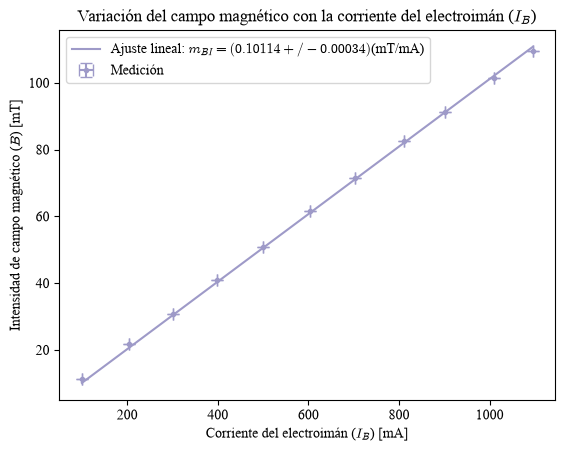

In [118]:
fig, ax = plt.subplots()

# Data points
data = workbook["BvsI"]
current = data["I_B[mA]"]
field = data["B[mT]"]

ax.errorbar(current, field,
            yerr=current1_stdv, xerr=field_stdv,
            fmt='.', label=f"Medición", capsize=4, color=colors1[0])

# Curve fit
fit_function = lambda I, m: m * I
popt, pcov = curve_fit(fit_function, current, field)
m_BI, stdv = popt[0], np.sqrt(pcov[0][0])
u_m_BI = ufloat(m_BI, stdv)

I = np.linspace(np.min(current), np.max(current), 100)
ax.plot(I, fit_function(I, m_BI), label=f"Ajuste lineal: $m_{{BI}}= ({u_m_BI})$(mT/mA)", color=colors1[0])
ax.set(xlabel="Corriente del electroimán ($I_B$) [mA]",
       ylabel="Intensidad de campo magnético ($B$) [mT]",
       title="Variación del campo magnético con la corriente del electroimán ($I_B$)")
plt.legend()

plt.savefig("BvsI.png", dpi=300)

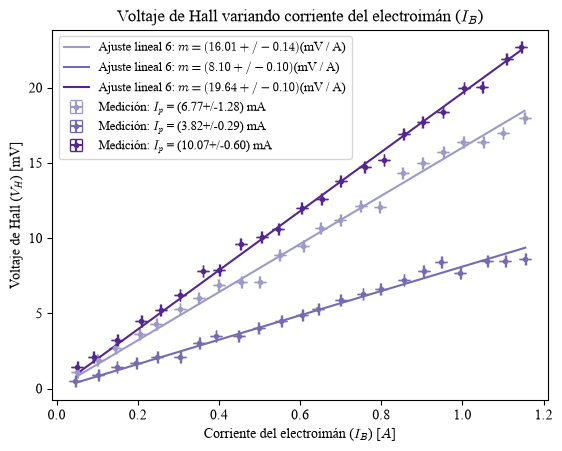

In [119]:
fig, ax = plt.subplots()
mean_Ips = []
ms = []

for sheet, color in zip(workbook.keys(), colors1):
    if "Ip" in sheet or "Theta" in sheet or "BvsI" in sheet:
        continue
    # Data points
    data = workbook[sheet]
    probe_current = data["I_P[mA]"]
    field_current = data["I_B[A]"]
    hall_voltage = data["V_H[mV]"]
    n, e, t = 1, 1, 1

    mean_Ip = np.mean(probe_current)
    stdv_Ip = np.std(probe_current)
    u_Ip = ufloat(mean_Ip, stdv_Ip)
    mean_Ips.append(u_Ip)
    
    u_hall_voltage = unp.uarray(hall_voltage, voltage_stdv)
    u_field_current = unp.uarray(field_current, current1_stdv)
    u_probe_current = unp.uarray(probe_current, current2_stdv)

    field_probe_current = field_current * probe_current
    u_Ib_Ip = u_field_current * u_probe_current
    
    ax.errorbar(field_current, hall_voltage,
                yerr=unp.std_devs(u_field_current), xerr=unp.std_devs(u_hall_voltage),
                fmt='.', label=f"Medición: $I_p$ = ({u_Ip:.2f}) mA", capsize=4, color=color)

    # Curve fit
    fit_function = lambda Ib, m: m * (Ib / (n*e*t))
    popt, pcov = curve_fit(fit_function, field_current, hall_voltage)
    m, stdv = popt[0], np.sqrt(pcov[0][0])
    u_m = ufloat(m, stdv)
    ms.append(u_m)

    Ib = np.linspace(np.min(field_current), np.max(field_current), 100)
    ax.plot(Ib, fit_function(Ib, m), label=f"Ajuste lineal {i + 1}: $m = ({u_m})$(mV / A)", color=color)
ax.set(xlabel="Corriente del electroimán ($I_B$) [$A$]",
       ylabel="Voltaje de Hall ($V_H$) [mV]",
       title="Voltaje de Hall variando corriente del electroimán ($I_B$)")
plt.legend(fontsize=9)

plt.savefig("VvsB.png", dpi=300)

In [120]:
d = 15E-6
RH_mean = 0
RHs = []
for Ip, m in zip(mean_Ips, ms):
    Ip = Ip / 1000 # A
    R_H = d * m * u_m_BI / Ip
    print(R_H)
    RHs.append(R_H)
    RH_mean += R_H / 3

print(RH_mean) # m^3 / C

0.0036+/-0.0007
0.00322+/-0.00025
0.00296+/-0.00018
0.00326+/-0.00025


In [121]:
workbook["VvsIp"].head(2)

,V_H[mV],I_P[mA],I_B[A],Unnamed: 3
0,1.7,0.81,0.576,NaN
1,3.2,1.56,0.576,NaN


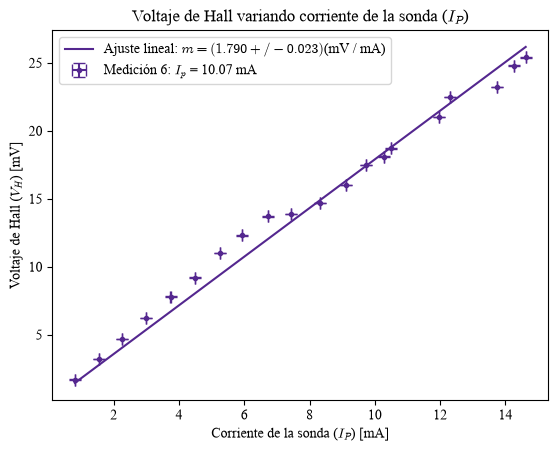

In [122]:
fig, ax = plt.subplots()

# Data points
data = workbook["VvsIp"]
probe_current = data["I_P[mA]"]
field_current = data["I_B[A]"]
hall_voltage = data["V_H[mV]"]
n, e, t = 1, 1, 1

u_hall_voltage = unp.uarray(hall_voltage, voltage_stdv)
u_field_current = unp.uarray(field_current, current1_stdv)
u_probe_current = unp.uarray(probe_current, current2_stdv)

ax.errorbar(probe_current, hall_voltage,
            yerr=unp.std_devs(u_probe_current), xerr=unp.std_devs(u_hall_voltage),
            fmt='.', label=f"Medición {i + 1}: $I_p$ = {mean_Ip:.2f} mA", capsize=4, color=colors1[2])

# Curve fit
fit_function = lambda Ip, m: m * (Ip / (n*e*t))
popt, pcov = curve_fit(fit_function, probe_current, hall_voltage)
m, stdv = popt[0], np.sqrt(pcov[0][0])
u_m = ufloat(m, stdv)

Ip = np.linspace(np.min(probe_current), np.max(probe_current), 100)
ax.plot(Ip, fit_function(Ip, m), label=f"Ajuste lineal: $m = ({u_m})$(mV / mA)", color=colors1[2])
ax.set(xlabel="Corriente de la sonda ($I_P$) [mA]",
       ylabel="Voltaje de Hall ($V_H$) [mV]",
       title="Voltaje de Hall variando corriente de la sonda ($I_P$)")
plt.legend()

plt.savefig("VvsI.png", dpi=300)

In [123]:
workbook["VvsTheta"].head(2)

,I_P[mA],Theta[deg],V_H[mV],I_B[A],Unnamed: 4,Unnamed: 5
0,7.16,0,7.0,0.498,NaN,NaN
1,6.95,15,6.2,0.498,NaN,NaN


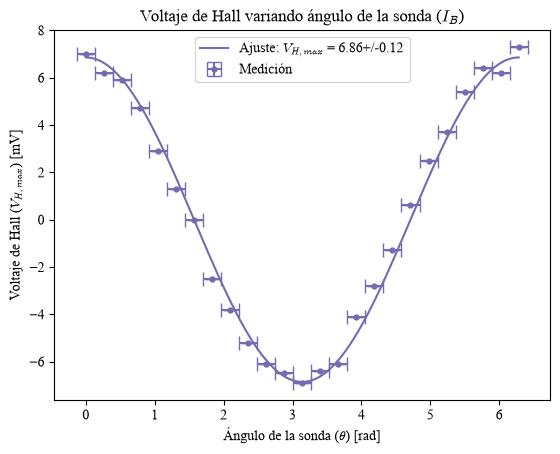

In [124]:
fig, ax = plt.subplots()

# Data points
data = workbook["VvsTheta"]
angle = (np.pi / 180) * data["Theta[deg]"] # rad
hall_voltage = data["V_H[mV]"]
angle_stdv = (np.pi / 180) * (15 / 2)

ax.errorbar(angle, hall_voltage,
          xerr=angle_stdv, yerr=voltage_stdv, fmt='.',
          label=f"Medición", markersize=7, capsize=5, color=colors1[1])

# Curve fit
fit_function = lambda theta, A: A * np.cos(theta)
popt, pcov = curve_fit(fit_function, angle, hall_voltage)
A, A_stdv = popt[0], np.sqrt(pcov[0][0])
A = ufloat(A, A_stdv)

theta = np.linspace(0, 2*np.pi, 1000)
ax.plot(theta, fit_function(theta, A.n), label=f"Ajuste: $V_{{H,max}}$ = {A}", color=colors1[1])

ax.set(xlabel="Ángulo de la sonda ($\\theta$) [rad]",
       ylabel="Voltaje de Hall ($V_{H,max}$) [mV]",
       title="Voltaje de Hall variando ángulo de la sonda ($I_B$)")
plt.legend()

plt.savefig("Vvstheta.png", dpi=300)

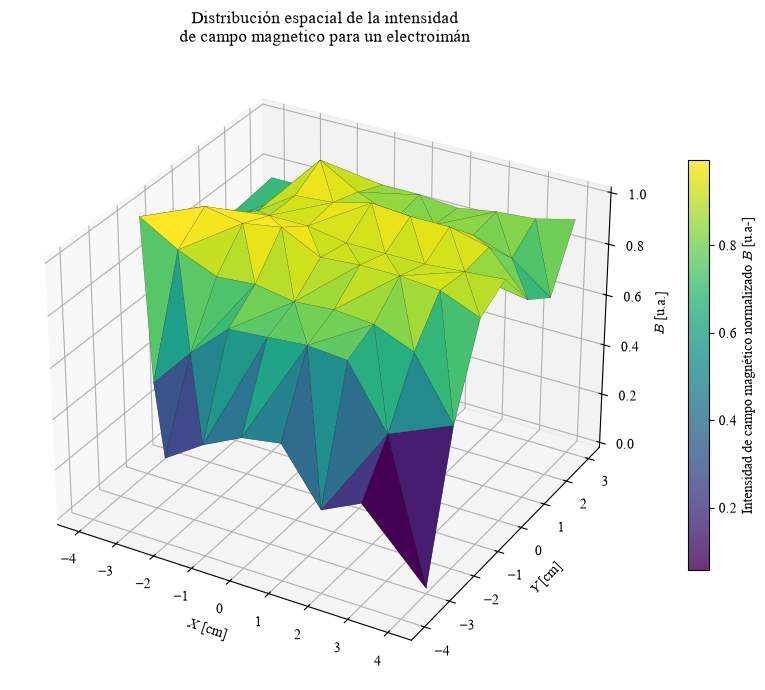

In [125]:
from scipy.interpolate import griddata


df = pd.read_excel("2026-10-09_HallEffect.xlsx", sheet_name="B2")

x = df["X_cm"].to_numpy()
y = -df["Y_cm"].to_numpy()
z = -df["B_mT"].to_numpy()
z = (z - np.min(z)) / (np.max(z) - np.min(z))


xi = np.linspace(x.min(), x.max(), 1000)
yi = np.linspace(y.min(), y.max(), 1000)

X, Y = np.meshgrid(xi, yi)


Z = griddata((x, y), z, (X, Y), method="linear")


fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")


superficie = ax.plot_surface(
    X, Y, Z,
    cmap="viridis",
    alpha=0.8,
    edgecolor="none"
)

surf = ax.plot_trisurf(
    x, y, z,
    cmap="viridis",
    edgecolor="black",
    linewidth=0.1,
    antialiased=True
)

ax.set_xlabel(r"$X$ [cm]")
ax.set_ylabel(r"$Y$ [cm]")
ax.set_zlabel(r"$B$ [u.a.]")

ax.set_title("Distribución espacial de la intensidad\nde campo magnetico para un electroimán")

fig.colorbar(
    superficie,
    ax=ax,
    shrink=0.65,
    label=r"Intensidad de campo magnético normalizado $B$ [u.a-]"
)

plt.tight_layout()
plt.savefig("B.png", dpi=300)

In [126]:
workbook = pd.read_excel("2026-10-09_HallEffect.xlsx", sheet_name=["BX", "BZ"])
workbook["BX"].head(3)

,I_P[mA],V_H[mV],X[cm]
0,6.61,4.8,0
1,7.15,4.5,1
2,7.41,4.7,2


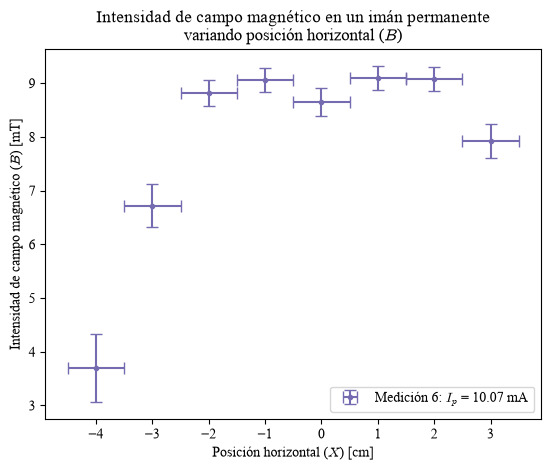

In [130]:
data = workbook["BX"]
X = data["X[cm]"]
V, Ip = data["V_H[mV]"], data["I_P[mA]"]
B = (d * V) / (Ip * RH_mean) * 1000 # mT
B = -B + 12

fig, ax = plt.subplots()
ax.errorbar(X, unp.nominal_values(B),
            yerr=unp.std_devs(B), xerr=0.5,
            fmt='.', label=f"Medición {i + 1}: $I_p$ = {mean_Ip:.2f} mA", capsize=4, color=colors1[1])
ax.set(xlabel="Posición horizontal ($X$) [cm]",
       ylabel="Intensidad de campo magnético ($B$) [mT]",
       title="Intensidad de campo magnético en un imán permanente\nvariando posición horizontal ($B$)")
plt.legend()

plt.savefig("Bx.png", dpi=300)

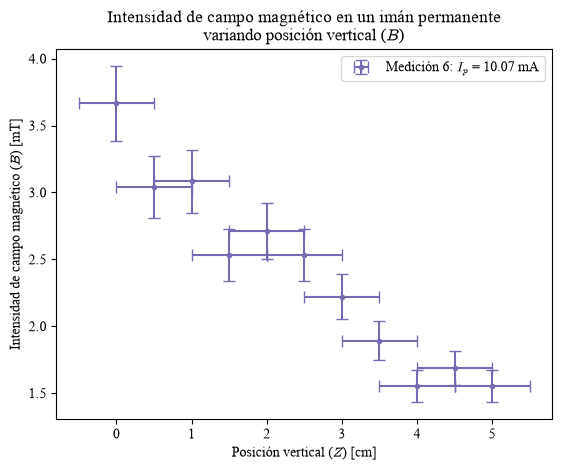

In [131]:
data = workbook["BZ"]
X = data["Z[cm]"]
V, Ip = data["V_H[mV]"], data["I_P[mA]"]
B = (d * V) / (Ip * RH_mean) * 1000 # mT

fig, ax = plt.subplots()
ax.errorbar(X, unp.nominal_values(B),
            yerr=unp.std_devs(B), xerr=0.5,
            fmt='.', label=f"Medición {i + 1}: $I_p$ = {mean_Ip:.2f} mA", capsize=4, color=colors1[1])
ax.set(xlabel="Posición vertical ($Z$) [cm]",
       ylabel="Intensidad de campo magnético ($B$) [mT]",
       title="Intensidad de campo magnético en un imán permanente\nvariando posición vertical ($B$)")
plt.legend()

plt.savefig("Bz.png", dpi=300)